# 코드 예시) Random 함수


In [ ]:
import random

In [ ]:
#random.random() -> 0.0에서 1.0사이의 실수 중에서 난수값 리턴
print(random.random())
# ex) 0.2664520652284096

#random.uniform(a, b) -> 괄호 안 두 수 사이의 실수 중에서 난수값을 리턴
print(random.uniform(10, 30))
# ex) 28.038707445386397

#random.randint(a, b) -> 괄호 안 두 수 사이의 정수 중에서 난수값을 리턴
print(random.randint(100,200))
# ex) 106

#random.choice(sample) 함수 -> sample에서 무작위로 하나를 선택하여 리턴
data = [1, 2, 3, 4, 5, 6, 7]
print(random.choice(data))
# ex) 5

#random.sample(sample, n) -> 입력으로 받은 sample 에서 정한 개수만큼  무작위로 뽑아 리턴함
data = [1, 2, 3, 4, 'apple', 'banna']
print(random.sample(data, 3))
# ex) ['apple', 2, 3]
print(random.sample(data, 3))
# ex) ['apple', 3, 'banna']
print(random.sample(data, 5))
# ex) [2, 3, 1, 'apple', 4]

# 실습1. 난수 히스토그램 그리기(파이썬 random 모듈)

In [34]:
# import packages
import matplotlib.pyplot as plt
from tqdm import tqdm # optional
import random

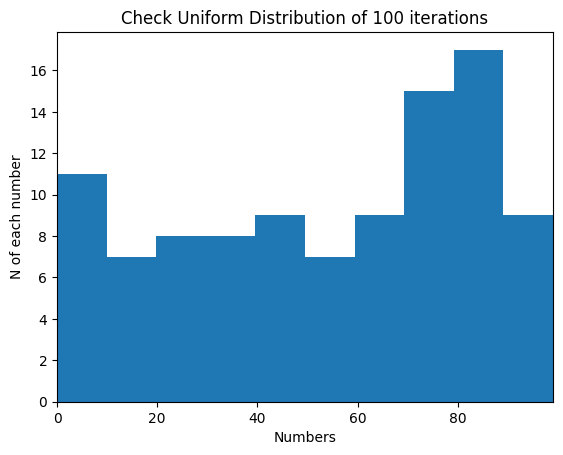

In [88]:
# 100번 수행
num_iterations = 100
random_integers = []


## write answer
for i in range(num_iterations) :
  next_x = random.randint(0, 99)
  random_integers.append(next_x)


fig = plt.figure()
plt.hist(random_integers)
plt.title(f"Check Uniform Distribution of {num_iterations} iterations")
plt.xlabel("Numbers")
plt.ylabel("N of each number")
plt.xlim([0, 99])
plt.show()

# 실습 2. Linear Congruential Generator(LCG) 구현  

X_(n+1) = (aX_n+C) mod m

LCG는 다음과 같은 인자들로 유일하게 결정됨  
  - 0 < m, 0 < a < m, 0 <= c < m, 0<=초기값 < m  

최대 주기 m을 가지기 위한 필요충분조건  

  - c와 m이 서로소, a-1이 m의 모든 소인수로 나뉨
  - m이 4의 배수면 a-1도 4의 배수

In [36]:
def lcg(seed, loop, m=2**32, a=214013, c=2531011):
    for i in range(loop):
        seed = (a * seed + c) % m
        yield seed

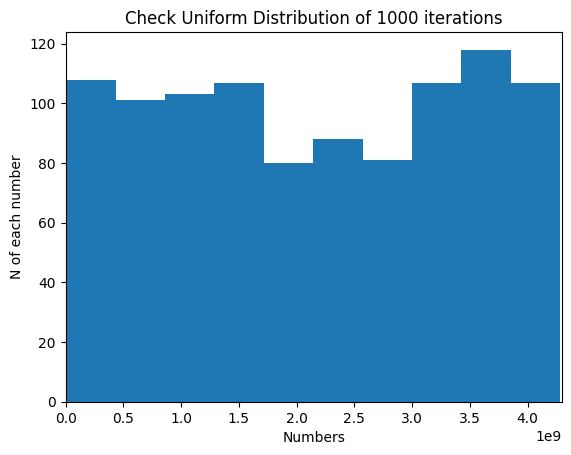

In [38]:
num_iterations = 1000
random_generator = lcg(seed=14, loop=num_iterations, m=2**32)
random_integers = []



## write answer
for value in random_generator :
  random_integers.append(value)



fig = plt.figure()
plt.hist(random_integers)
plt.title(f"Check Uniform Distribution of {num_iterations} iterations")
plt.xlabel("Numbers")
plt.ylabel("N of each number")
plt.xlim([0, 2**32])
plt.show()

# 실습 2-2 난수들 중 Uniform Distribution 확인  


In [90]:
# LCG
from collections import defaultdict

for num_iterations in [1000,10000,100000]:
    ## write answer
    random_generator = lcg(seed=14, loop=num_iterations, m=2**32)
    random_integers = []


    ## write answer
    for value in random_generator :
        random_integers.append(value)


    normalized_vals = [val / (2**32) for val in random_integers]
    sample_mean = sum(normalized_vals) / num_iterations
    error = abs(sample_mean - 0.5)
    print(f"LCG 시행횟수 {num_iterations}에서의 uniform distribution 오차 : {error}")

LCG 시행횟수 1000에서의 uniform distribution 오차 : 0.0019449386289343007
LCG 시행횟수 10000에서의 uniform distribution 오차 : 0.0007839456295594127
LCG 시행횟수 100000에서의 uniform distribution 오차 : 0.0004651833731308397


In [92]:
# 메르센 트위스터
from collections import defaultdict

for num_iterations in [1000,10000,100000]:

    ## write answer
    random_integers = []



    for _ in range(num_iterations):
        ## write answer
        next_x = random.randint(0, 2**32-1)
        random_integers.append(next_x)


    normalized_vals = [val / (2**32) for val in random_integers]
    sample_mean = sum(normalized_vals) / num_iterations
    error = abs(sample_mean - 0.5)
    print(f"메르센 트위스터 시행횟수 {num_iterations}에서의 uniform distribution 오차 : {error}")

메르센 트위스터 시행횟수 1000에서의 uniform distribution 오차 : 0.01581808177125643
메르센 트위스터 시행횟수 10000에서의 uniform distribution 오차 : 0.0009948709575459125
메르센 트위스터 시행횟수 100000에서의 uniform distribution 오차 : 0.001152729251813145


# 실습 3. 주사위 합이 8인 경우

In [41]:
# 출력시 컬러 지원 가능 모듈 설치
!pip install termcolor
from termcolor import colored
!pip install colorama
from colorama import init, Fore, Back, Style


In [93]:
def roll_dice():
    ## write answer
    dice1 = random.randint(1, 6)
    dice2 = random.randint(1, 6)
    return [dice1, dice2]

In [104]:
dice_tries = []
num_iterations = 100
hits = 0
for i in range(num_iterations):
    roll_result = roll_dice()

    if (roll_result[0] + roll_result[1] == 8) :
          hits += 1

    dice_tries.append(roll_result)


print("="*100)
print(colored("* 두 주사위의 합이 8인 경우에는 cyan 색의 음영이 들어가 있음 *", 'red'))

for i in range(num_iterations):
    ## write answer
    if dice_tries[i][0] + dice_tries[i][1] == 8:
        print(colored(f"try {i}:{dice_tries[i][0]} {dice_tries[i][1]}", on_color="on_cyan"), end='   ')
    else:
        print(f"try {i}:{dice_tries[i][0]} {dice_tries[i][1]}", end='   ')
    if (i+1)%5 == 0 :
        print()


print(colored("\n실제 값 : 0.138889", "red"))
print(colored(f"계산된 값 : {round(hits / num_iterations,6)}", "red"))
print(colored(f"오차율 : {abs(hits / num_iterations - 5/36) / (5/36) * 100} %", "red"))
print("="*100)


* 두 주사위의 합이 8인 경우에는 cyan 색의 음영이 들어가 있음 *
try 0:4 6   try 1:1 6   try 2:6 1   try 3:4 2   try 4:2 5   
try 5:2 5   try 6:2 2   try 7:5 4   try 8:2 4   try 9:1 5   
try 10:2 5   try 11:3 3   try 12:2 4   try 13:6 3   try 14:3 1   
try 15:3 2   try 16:6 3   try 17:1 1   try 18:6 6   try 19:3 4   
try 20:2 1   try 21:3 3   try 22:6 6   try 23:1 3   try 24:5 6   
try 25:3 1   try 26:4 5   try 27:3 6   try 28:4 6   try 29:4 5   
try 30:1 6   try 31:2 5   try 32:3 5   try 33:6 6   try 34:5 5   
try 35:6 5   try 36:3 4   try 37:2 2   try 38:4 6   try 39:4 2   
try 40:5 4   try 41:1 6   try 42:6 6   try 43:4 3   try 44:2 5   
try 45:3 2   try 46:1 2   try 47:3 3   try 48:3 5   try 49:5 1   
try 50:2 5   try 51:2 4   try 52:2 2   try 53:6 3   try 54:3 2   
try 55:3 5   try 56:6 1   try 57:3 2   try 58:3 1   try 59:4 3   
try 60:4 2   try 61:5 1   try 62:3 1   try 63:3 4   try 64:1 4   
try 65:5 3   try 66:3 4   try 67:5 4   try 68:4 2   try 69:1 4   
try 70:4 1   try 71:6 4   try 72:6 2   try 73